# 17 Case study: exploring a dataset from start to finish

Everything from the previous notebooks applied to one question:

*Which organisms and specimens show the most ciprofloxacin resistance, and has it changed over the year?*

This is the kind of exploration done before any modelling.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

## 1. Load

Start from the raw file and repeat the cleaning from notebook 12 as one function,
so the analysis never depends on a file someone edited by hand.

In [2]:
def load_isolates(path):
    d = pd.read_csv(path).drop_duplicates()
    d["specimen"] = d["specimen"].str.strip().str.capitalize()
    for col in ["ciprofloxacin", "ceftriaxone"]:
        d[col] = d[col].str.strip().str.upper().replace({"N/A": np.nan, "": np.nan})
    d["collected"] = pd.to_datetime(d["collected"], format="%d/%m/%Y")
    d.loc[~d["temp_c"].between(30, 45), "temp_c"] = np.nan
    return d

iso = load_isolates("../data/isolates_raw.csv")
patients = pd.read_csv("../data/patients.csv")
iso = iso.merge(patients[["patient_id", "site", "sex", "age"]], on="patient_id",
                how="left", validate="many_to_one")
print(iso.shape)
iso.head()

(400, 12)


,isolate_id,patient_id,collected,specimen,organism,ciprofloxacin,ceftriaxone,mic_cipro,temp_c,site,sex,age
0,ISO-0001,P0114,2025-03-26,Blood,E. coli,R,S,<=0.06,36.8,Kampala,F,33
1,ISO-0002,P0212,2025-04-10,Urine,P. aeruginosa,R,R,2,37.0,Mbarara,M,72
2,ISO-0003,P0019,2025-06-24,Blood,E. coli,S,S,0.5,37.6,Kampala,F,74
3,ISO-0004,P0097,2025-05-19,Wound swab,S. aureus,R,R,0.25,37.9,Mbarara,M,30
4,ISO-0005,P0038,2025-02-18,Wound swab,K. pneumoniae,S,S,1,38.6,Gulu,F,1


## 2. Check the data

In [3]:
print(iso.isna().sum()[lambda s: s > 0])
print(iso["isolate_id"].is_unique)

ciprofloxacin    24
ceftriaxone      31
temp_c            6
dtype: int64
True


## 3. Describe

In [4]:
print(iso["organism"].value_counts())
print(iso["specimen"].value_counts())

organism
E. coli          152
K. pneumoniae     86
S. aureus         85
P. aeruginosa     77
Name: count, dtype: int64
specimen
Blood         149
Urine         111
Wound swab     72
Stool          68
Name: count, dtype: int64


In [5]:
tested = iso.dropna(subset=["ciprofloxacin"]).assign(resistant=lambda d: d["ciprofloxacin"] == "R")
print(f"{len(tested)} isolates tested, {tested['resistant'].mean():.1%} resistant to ciprofloxacin")

376 isolates tested, 43.1% resistant to ciprofloxacin


## 4. Resistance by organism and specimen

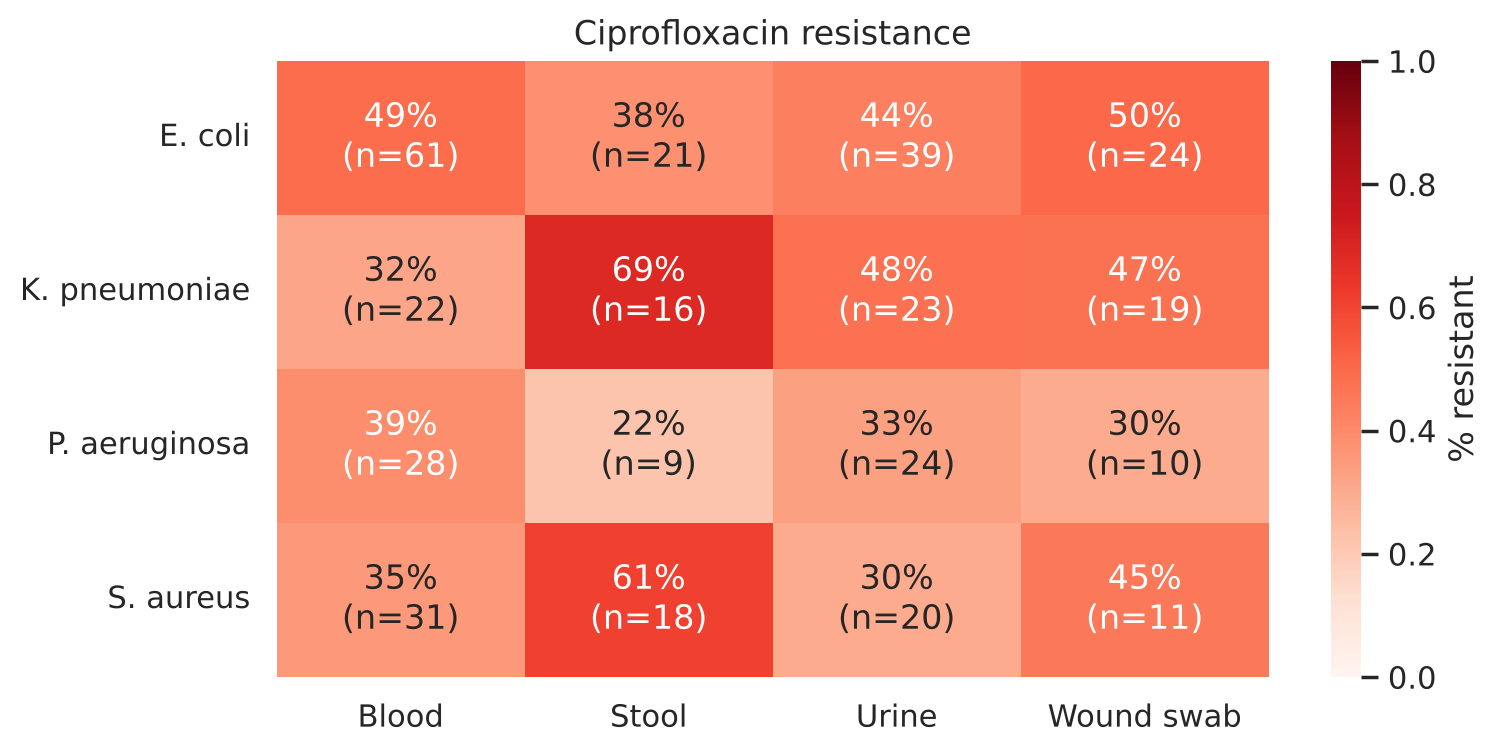

In [6]:
table = (
    tested
    .groupby(["organism", "specimen"])
    .agg(n=("resistant", "size"), pct_r=("resistant", "mean"))
    .reset_index()
)
heat = table.pivot(index="organism", columns="specimen", values="pct_r")
n = table.pivot(index="organism", columns="specimen", values="n")

labels = (heat * 100).round(0).astype("Int64").astype(str) + "%\n(n=" + n.astype(str) + ")"
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(heat, annot=labels, fmt="", cmap="Reds", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "% resistant"})
ax.set(xlabel="", ylabel="", title="Ciprofloxacin resistance")
plt.show()

Small cells (low n) give unstable percentages. Look at the counts before reading the colours.

## 5. Change over time

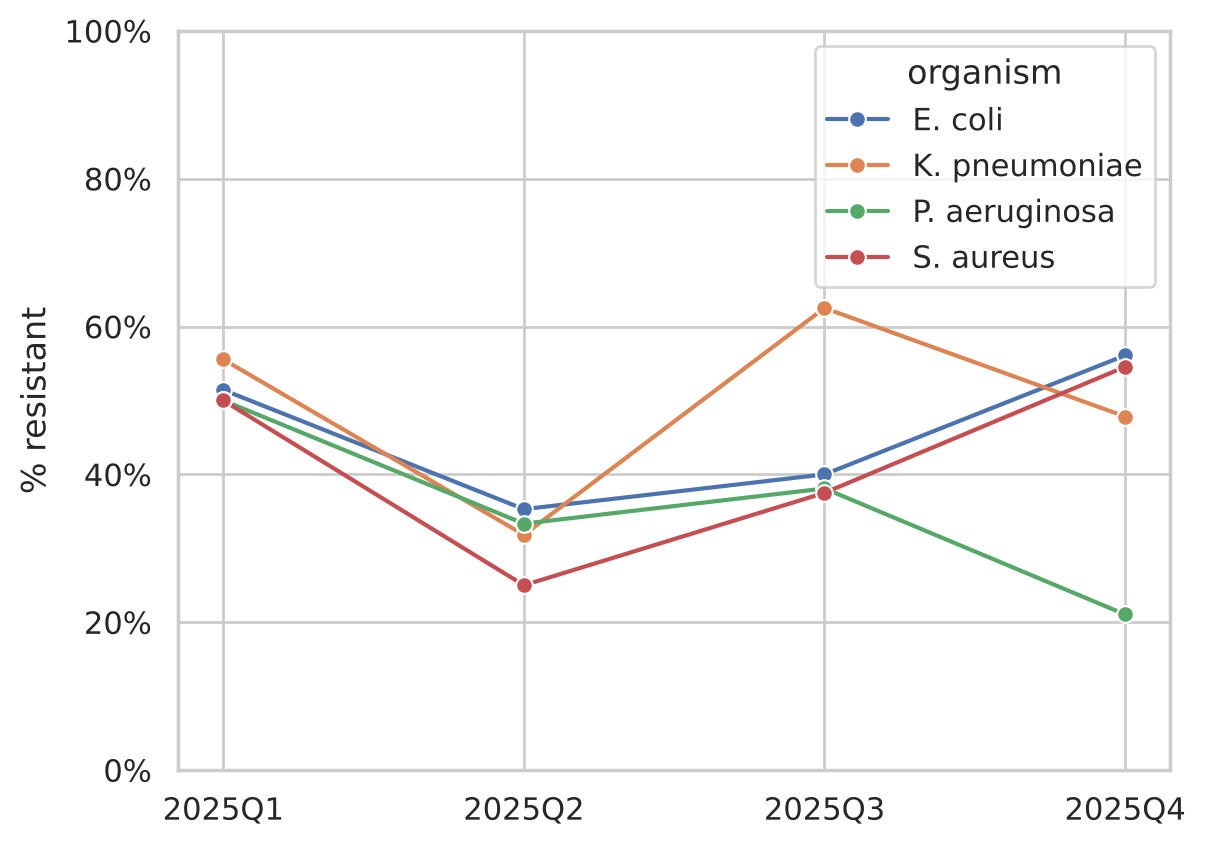

In [7]:
monthly = (
    tested
    .groupby([tested["collected"].dt.to_period("Q").astype(str), "organism"])["resistant"]
    .agg(["mean", "size"])
    .reset_index()
    .rename(columns={"collected": "quarter"})
)
ax = sns.lineplot(data=monthly, x="quarter", y="mean", hue="organism", marker="o")
ax.set(ylabel="% resistant", xlabel="", ylim=(0, 1))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

## 6. Does resistance relate to patient characteristics?

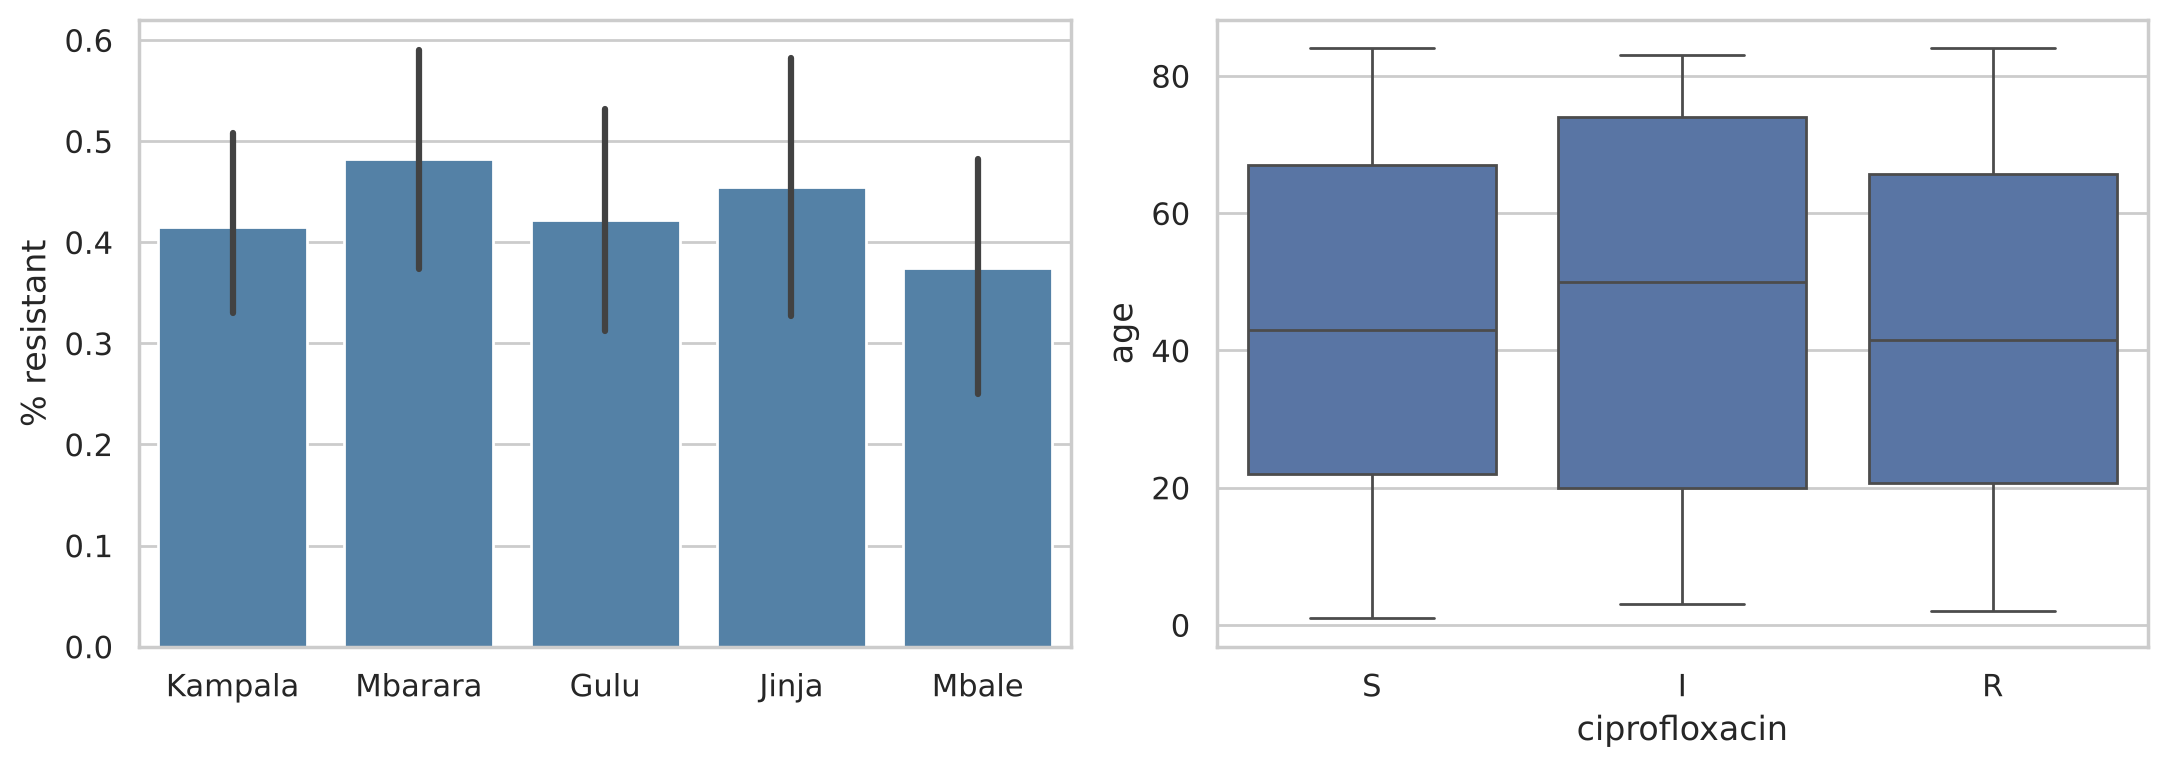

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=tested, x="site", y="resistant", ax=axes[0], color="steelblue")
axes[0].set(ylabel="% resistant", xlabel="")
sns.boxplot(data=tested, x="ciprofloxacin", y="age", order=["S", "I", "R"], ax=axes[1])
fig.tight_layout()
plt.show()

## 7. Co-resistance

Are isolates resistant to ciprofloxacin also resistant to ceftriaxone?

In [9]:
pd.crosstab(tested["ciprofloxacin"], tested["ceftriaxone"], margins=True)

ceftriaxone,I,R,S,All
ciprofloxacin,,,,
I,0,9,11,20
R,9,69,70,148
S,10,74,94,178
All,19,152,175,346


## 8. Write down what you found

- the overall resistance rate and which organism / specimen groups are highest
- whether there is a visible time trend, and how many isolates each point rests on
- data problems found and fixed: duplicates, inconsistent case, impossible temperatures, MICs stored as text

These are simulated data, so the patterns are made up. The steps are the ones you would use on real data,
and the cleaned table is the starting point for the machine learning guide.